In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|pillow) "
# Зафиксируем сведения о среде.
"""
name, memory.total [MiB]
Tesla T4, 15360 MiB
diffusers                             0.41.0
pillow                                11.3.0
torch                                 2.11.0+cu130
transformers                          5.20.2
"""

name, memory.total [MiB]
Tesla T4, 15360 MiB
diffusers                             0.41.0
pillow                                11.3.0
torch                                 2.11.0+cu130
transformers                          5.20.2


'\nname, memory.total [MiB]\nTesla T4, 15360 MiB\ndiffusers                             0.41.0\npillow                                11.3.0\ntorch                                 2.11.0+cu130\ntransformers                          5.20.2\n'

In [2]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)

    # Добавление библиотек для лабораторной. Вывод: Overwriting lab05_lib.py

Overwriting lab05_lib.py


Цель эксперимента: проверить, совпадают ли изображения, созданные моделью stabilityai/sd-turbo при одинаковом запросе и seed, если генератор случайного шума работает на CPU и GPU.

Гипотеза: при одинаковом seed генераторы CPU и GPU могут создавать разные последовательности случайных чисел. Поэтому изображения могут различаться даже при одинаковой модели и параметрах генерации.

Условие сравнения: CPU против GPU.

Вариант: 21.

Seed: 1021.

Критерий: PSNR не ниже 40 дБ — практическое совпадение; ниже 40 дБ — различие превышает установленный допуск.

In [3]:
import torchao
print(torchao.__version__)
!pip install --upgrade --force-reinstall "torchao>=0.15.0"
#Запуск следующего кода показал что версия torch была меньше, чем необходимый минимум. Исправил это через эти команды.

0.18.0


In [4]:
import json
import pathlib
import platform
import sys
import time

import torch
import diffusers
import transformers
import PIL
from IPython.display import display

import lab05_lib as L

# Папка для результатов варианта 21
out = pathlib.Path("artifacts/variant_21")
out.mkdir(parents=True, exist_ok=True)

# Параметры варианта
variant = 21
prompt = L.BRIEFS[3]
seed = 1000 + variant

print("Вариант:", variant)
print("Seed:", seed)
print("Бриф:", prompt)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "не найден")

# Загрузка модели
start = time.perf_counter()
pipe = L.load_pipe()
load_seconds = round(time.perf_counter() - start, 2)

print("Модель загружена за", load_seconds, "секунд")

#Загружаем модель для лабораторной из интернета. Вывод:
"""
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
Вариант: 21
Seed: 1021
Бриф: visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people
GPU: Tesla T4
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
model_index.json: 100%
 616/616 [00:00<00:00, 16.6kB/s]
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Download complete:
 2.58GB,  216MB/s
Reconstruction complete: 100%
 2.58GB / 2.58GB, 75.9MB/s
Fetching 12 files: 100%
 12/12 [00:32<00:00,  4.13s/it]
Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
WARNING:huggingface_hub.utils._http:Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
Loading pipeline components...: 100%
 5/5 [00:00<00:00,  7.88it/s]
Loading weights: 100%
 372/372 [00:00<00:00, 4026.31it/s]
Модель загружена за 36.37 секунд
"""

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


Вариант: 21
Seed: 1021
Бриф: visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people
GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Модель загружена за 36.37 секунд


{
  "variant": 21,
  "seed": 1021,
  "condition": "CPU generator vs GPU generator",
  "model": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
  "image_size": [
    512,
    512
  ],
  "sha256_A": "8e1902724af373b03e090516c24775f9ba3fb67ea5b4063905bac38e786e7e43",
  "sha256_B": "38230f19d177194dd3f675d4fafb159772527d9d55a54284bfe1e76793b3c4f2",
  "pixel_equal": false,
  "max_abs_diff": 184,
  "psnr_db": 15.174142497875824,
  "verdict": "different",
  "generation_seconds_A": 0.27,
  "generation_seconds_B": 0.27
}
Изображение A — CPU:


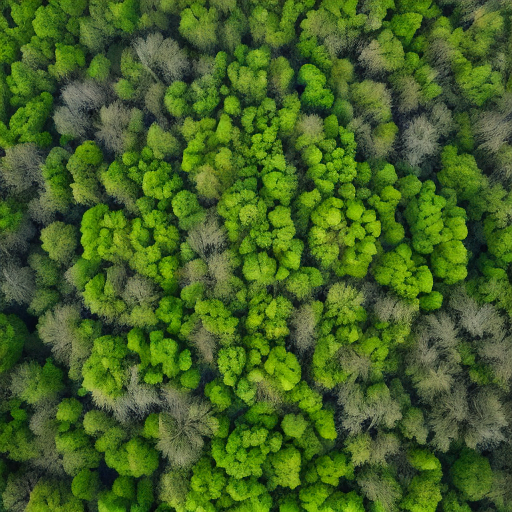

Изображение B — GPU:


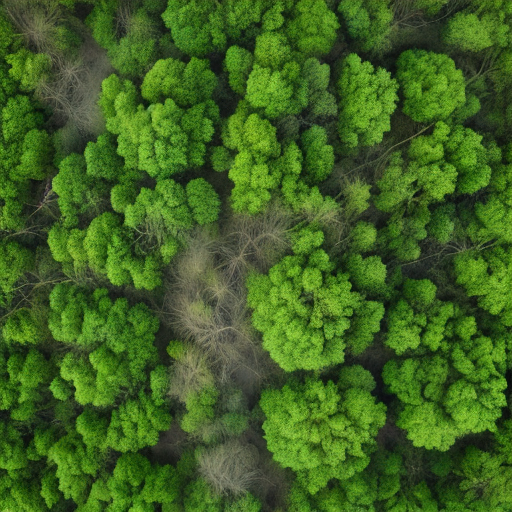

'\n{\n  "variant": 21,\n  "seed": 1021,\n  "condition": "CPU generator vs GPU generator",\n  "model": "stabilityai/sd-turbo",\n  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",\n  "prompt": "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",\n  "image_size": [\n    512,\n    512\n  ],\n  "sha256_A": "8e1902724af373b03e090516c24775f9ba3fb67ea5b4063905bac38e786e7e43",\n  "sha256_B": "38230f19d177194dd3f675d4fafb159772527d9d55a54284bfe1e76793b3c4f2",\n  "pixel_equal": false,\n  "max_abs_diff": 184,\n  "psnr_db": 15.174142497875824,\n  "verdict": "different",\n  "generation_seconds_A": 0.3,\n  "generation_seconds_B": 0.3\n}\n'

In [7]:
# Прогревочный вызов: не входит в сравнение
L.generate(pipe, prompt, seed=seed + 100)[0]

# A: генератор случайного шума на CPU
start = time.perf_counter()
img_a = L.generate(
    pipe, prompt, seed,
    gen_device="cpu"
)[0]
time_a = round(time.perf_counter() - start, 2)

# B: генератор случайного шума на GPU
start = time.perf_counter()
img_b = L.generate(
    pipe, prompt, seed,
    gen_device="cuda"
)[0]
time_b = round(time.perf_counter() - start, 2)

# Сохранение изображений
path_a = out / "result_A_cpu.png"
path_b = out / "result_B_gpu.png"

bytes_a = L.png_bytes(img_a)
bytes_b = L.png_bytes(img_b)

path_a.write_bytes(bytes_a)
path_b.write_bytes(bytes_b)

# Метрики сравнения
psnr = L.psnr_db(img_a, img_b)
pixel_equal = bool(
    (L.to_arr(img_a) == L.to_arr(img_b)).all()
)

metrics = {
    "variant": variant,
    "seed": seed,
    "condition": "CPU generator vs GPU generator",
    "model": L.MODEL_ID,
    "revision": L.REVISION,
    "prompt": prompt,
    "image_size": list(img_a.size),
    "sha256_A": L.sha(bytes_a),
    "sha256_B": L.sha(bytes_b),
    "pixel_equal": pixel_equal,
    "max_abs_diff": L.max_abs_diff(img_a, img_b),
    "psnr_db": psnr,
    "verdict": L.classify(psnr, tol_db=40.0),
    "generation_seconds_A": time_a,
    "generation_seconds_B": time_b,
}

(out / "comparison.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(json.dumps(metrics, ensure_ascii=False, indent=2))

print("Изображение A — CPU:")
display(img_a)

print("Изображение B — GPU:")
display(img_b)
#Этот код сохраняет оба изображения и метрики сравнения. Файл comparison.json содержит результаты, необходимые для последующего анализа. Вывод:
"""
{
  "variant": 21,
  "seed": 1021,
  "condition": "CPU generator vs GPU generator",
  "model": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
  "image_size": [
    512,
    512
  ],
  "sha256_A": "8e1902724af373b03e090516c24775f9ba3fb67ea5b4063905bac38e786e7e43",
  "sha256_B": "38230f19d177194dd3f675d4fafb159772527d9d55a54284bfe1e76793b3c4f2",
  "pixel_equal": false,
  "max_abs_diff": 184,
  "psnr_db": 15.174142497875824,
  "verdict": "different",
  "generation_seconds_A": 0.3,
  "generation_seconds_B": 0.3
}
"""

# По изображениям видно: генерации разные, хоть seed и время генерации одно и тоже. Это так же наблюдается и в метриках.

{
  "seed": 1021,
  "pixel_equal": false,
  "psnr_db": 15.390253250679468,
  "verdict": "different"
}
Первое изображение:


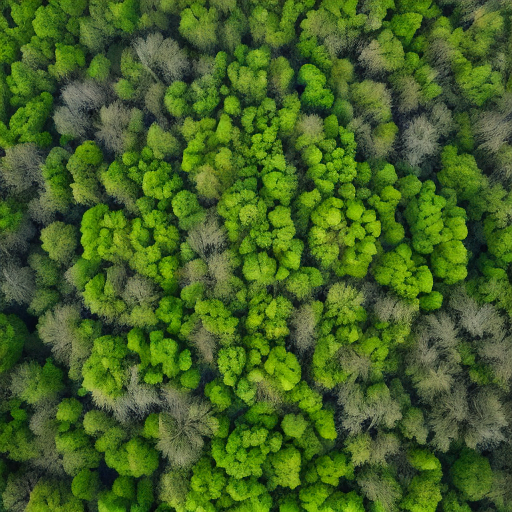

Второе изображение:


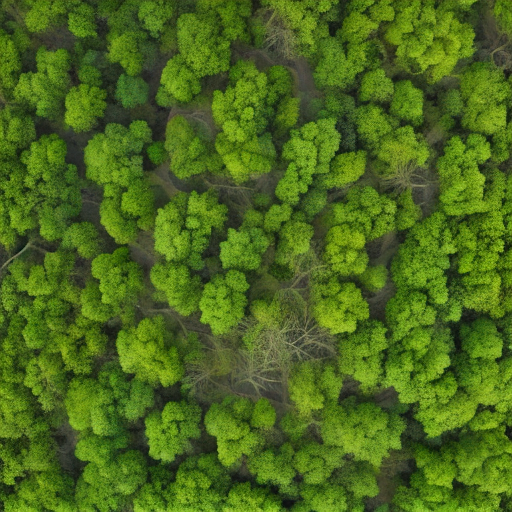

In [8]:
# Демонстрация ошибки: повторное использование одного генератора

import time
import torch
import json
from IPython.display import display

# Один генератор с фиксированным seed
shared_generator = torch.Generator(device="cpu").manual_seed(seed)

# Два последовательных вызова с одним и тем же объектом генератора
img_error_a = pipe(
    prompt,
    num_inference_steps=1,
    guidance_scale=0.0,
    generator=shared_generator,
    height=512,
    width=512,
).images[0]

img_error_b = pipe(
    prompt,
    num_inference_steps=1,
    guidance_scale=0.0,
    generator=shared_generator,
    height=512,
    width=512,
).images[0]

# Сравнение результатов
error_psnr = L.psnr_db(img_error_a, img_error_b)
error_equal = bool(
    (L.to_arr(img_error_a) == L.to_arr(img_error_b)).all()
)

print(json.dumps({
    "seed": seed,
    "pixel_equal": error_equal,
    "psnr_db": error_psnr,
    "verdict": L.classify(error_psnr, tol_db=40.0)
}, ensure_ascii=False, indent=2))

print("Первое изображение:")
display(img_error_a)

print("Второе изображение:")
display(img_error_b)

"""
Вывод: при повторном использовании одного объекта torch.Generator состояние генератора изменяется после первого вызова.
Поэтому второй вызов модели получает другую последовательность случайных чисел, и полученное изображение отличается от первого, несмотря на одинаковые остальные параметры.
"""

In [9]:
import json
import hashlib
import platform
import torch
import diffusers
import transformers
import PIL
from pathlib import Path

out = Path("artifacts/variant_21")
out.mkdir(parents=True, exist_ok=True)

# Базовый результат — изображение A из основного эксперимента
baseline_path = out / "result.png"
img_a.save(baseline_path, format="PNG")

# Хеш сохранённого файла
baseline_bytes = baseline_path.read_bytes()
baseline_sha256 = hashlib.sha256(baseline_bytes).hexdigest()

manifest = {
    "variant": 21,
    "seed": 1021,
    "model": L.MODEL_ID,
    "revision": L.REVISION,
    "prompt": prompt,
    "image_size": list(img_a.size),
    "num_inference_steps": 1,
    "guidance_scale": 0.0,
    "generator_device": "cpu",
    "dtype": "float16",
    "device": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "cpu"
    ),
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "diffusers_version": diffusers.__version__,
    "transformers_version": transformers.__version__,
    "pillow_version": PIL.__version__,
    "sha256": baseline_sha256,
    "comparison_psnr_db": psnr,
    "comparison_verdict": L.classify(psnr, tol_db=40.0),
}

manifest_path = out / "manifest.json"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Сохранён базовый результат:", baseline_path)
print("Сохранён манифест:", manifest_path)
print(json.dumps(manifest, ensure_ascii=False, indent=2))

# Сохранение всех результатов эксперимента

Сохранён базовый результат: artifacts/variant_21/result.png
Сохранён манифест: artifacts/variant_21/manifest.json
{
  "variant": 21,
  "seed": 1021,
  "model": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
  "image_size": [
    512,
    512
  ],
  "num_inference_steps": 1,
  "guidance_scale": 0.0,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "python_version": "3.13.16",
  "torch_version": "2.11.0+cu130",
  "diffusers_version": "0.41.0",
  "transformers_version": "5.20.2",
  "pillow_version": "11.3.0",
  "sha256": "8e1902724af373b03e090516c24775f9ba3fb67ea5b4063905bac38e786e7e43",
  "comparison_psnr_db": 15.174142497875824,
  "comparison_verdict": "different"
}
